# Heart Disease Prediction Using SVM

Cleaned version of the original notebook. Pipeline: dataset → preprocessing → EDA → SVM → kernel comparison → hyperparameter tuning → evaluation → pickle → terminal-style patient input.

In [1]:
import os
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("=" * 60)
print("HEART DISEASE PREDICTION USING SVM")
print("=" * 60)


HEART DISEASE PREDICTION USING SVM


In [2]:
# Load the same dataset used in the original notebook.
dataset_path = r"C:\Users\kotha\Downloads\Heart_disease_svm\heart_disease_data.csv"

# If the CSV is in the same folder as this notebook, use this instead:
# dataset_path = "heart_disease_data.csv"

df = pd.read_csv(dataset_path)

print("\nDataset loaded successfully!")
print("Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())



Dataset loaded successfully!
Shape: (606, 14)

First 5 rows:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   48    1   0       130   256    1        0      150      1      0.0      2   
1   61    1   0       148   203    0        1      161      0      0.0      2   
2   44    0   2       118   242    0        1      149      0      0.3      1   
3   47    1   0       110   275    0        0      118      1      1.0      1   
4   56    1   3       120   193    0        0      162      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   1     3       0  
2   1     2       1  
3   1     2       0  
4   0     3       1  


In [3]:
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())



Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 606 entries, 0 to 605
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       606 non-null    int64  
 1   sex       606 non-null    int64  
 2   cp        606 non-null    int64  
 3   trestbps  606 non-null    int64  
 4   chol      606 non-null    int64  
 5   fbs       606 non-null    int64  
 6   restecg   606 non-null    int64  
 7   thalach   606 non-null    int64  
 8   exang     606 non-null    int64  
 9   oldpeak   606 non-null    float64
 10  slope     606 non-null    int64  
 11  ca        606 non-null    int64  
 12  thal      606 non-null    int64  
 13  target    606 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 66.4 KB

Statistical summary:
              age         sex        

In [4]:
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Fill numeric missing values with median.
df = df.fillna(df.median(numeric_only=True))

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)



Missing values before cleaning:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Missing values after cleaning:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate rows: 304
Shape after removing duplicates: (302, 14)


In [5]:
print("\nTarget distribution:")
print(df["target"].value_counts())
print("\nTarget meaning: 0 = No heart disease, 1 = Heart disease")



Target distribution:
target
1    164
0    138
Name: count, dtype: int64

Target meaning: 0 = No heart disease, 1 = Heart disease


In [6]:
# Show some actual examples from the dataset with target = 0

no_disease_examples = df[df["target"] == 0]

print(no_disease_examples.head(10))

    age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
0    48    1   0       130   256    1        0      150      1      0.0   
1    61    1   0       148   203    0        1      161      0      0.0   
3    47    1   0       110   275    0        0      118      1      1.0   
5    68    1   0       144   193    1        1      141      0      3.4   
6    63    1   0       130   254    0        0      147      0      1.4   
7    35    1   0       126   282    0        0      156      1      0.0   
9    63    0   0       108   269    0        1      169      1      1.8   
18   57    1   0       110   335    0        1      143      1      3.0   
20   62    0   0       140   268    0        0      160      0      3.6   
21   59    1   3       170   288    0        0      159      0      0.2   

    slope  ca  thal  target  
0       2   2     3       0  
1       2   1     3       0  
3       1   1     2       0  
5       1   2     3       0  
6       1   1     3     

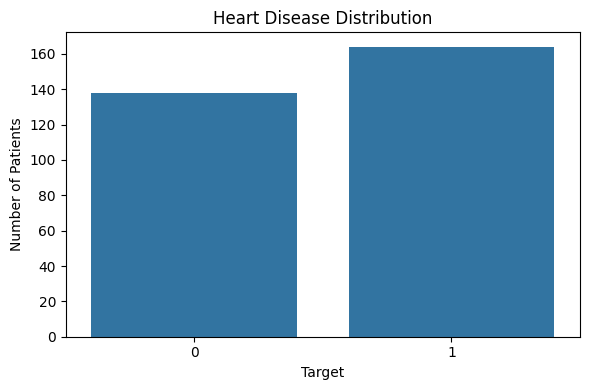

In [7]:
# EDA 1: target distribution
plt.figure(figsize=(6, 4))
sns.countplot(x="target", data=df)
plt.title("Heart Disease Distribution")
plt.xlabel("Target")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()


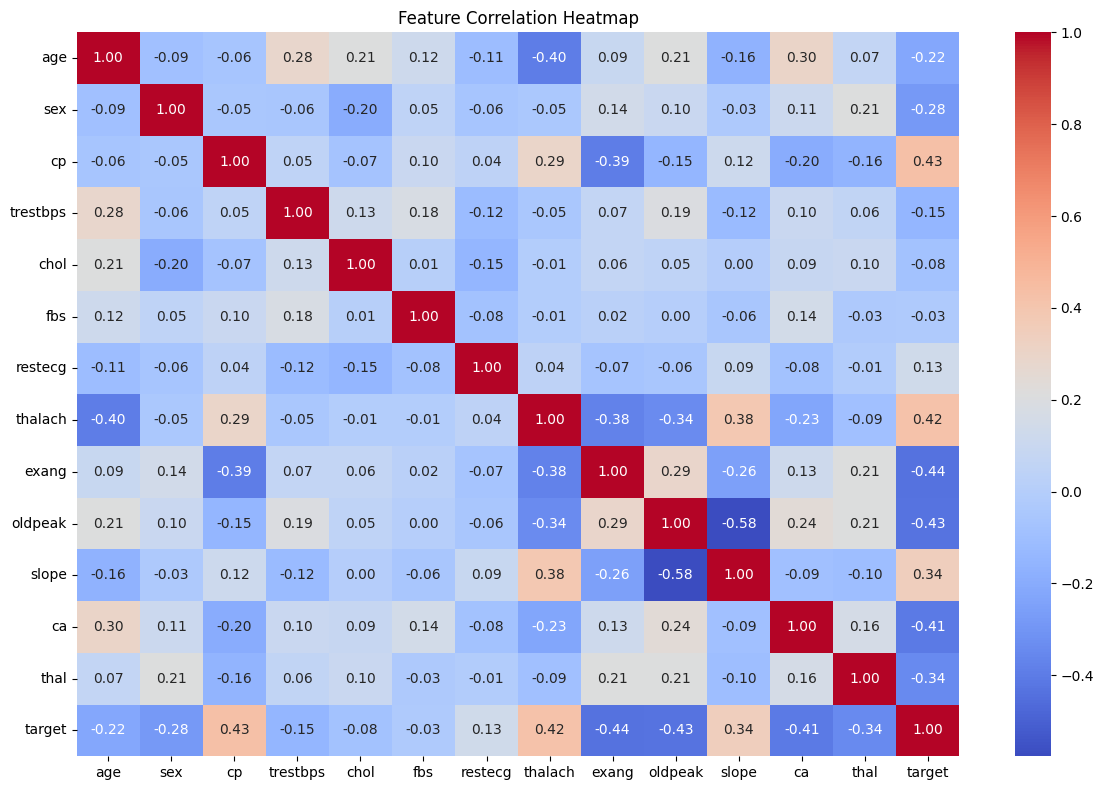

In [8]:
# EDA 2: correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [9]:
# Separate features and target
X = df.drop("target", axis=1)
y = df["target"]

print("Feature columns:")
print(X.columns.tolist())
print("Number of features:", X.shape[1])

# 80/20 split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Feature columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Number of features: 13

Training shape: (241, 13)
Testing shape: (61, 13)


In [10]:
# Fit scaler ONLY on training data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling completed.")



Feature scaling completed.


In [11]:
# Basic SVM
basic_model = SVC(kernel="rbf")
basic_model.fit(X_train_scaled, y_train)

basic_pred = basic_model.predict(X_test_scaled)
basic_accuracy = accuracy_score(y_test, basic_pred)

print("\nBasic RBF SVM accuracy: {:.2f}%".format(basic_accuracy * 100))



Basic RBF SVM accuracy: 80.33%


In [12]:
# Compare SVM kernels
kernels = ["linear", "rbf", "poly"]
print("\nSVM kernel comparison:")

for kernel in kernels:
    model = SVC(kernel=kernel)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, pred)
    print(f"{kernel.upper():<8} kernel accuracy: {acc * 100:.2f}%")



SVM kernel comparison:
LINEAR   kernel accuracy: 85.25%
RBF      kernel accuracy: 80.33%
POLY     kernel accuracy: 85.25%


In [13]:
# Hyperparameter tuning 
param_grid = { 
    "C": [0.1, 1, 10, 100], 
    "gamma": ["scale", 0.01, 0.1, 1], 
    "kernel": ["linear", "rbf", "poly"] 
} 
 
print("\nRunning GridSearchCV...") 
grid_search = GridSearchCV( 
    SVC(), 
    param_grid=param_grid, 
    cv=3, 
    scoring="accuracy", 
    n_jobs=-1 
) 
grid_search.fit(X_train_scaled, y_train) 
 
print("Grid search completed.") 
print("Best parameters:", grid_search.best_params_) 
print("Best cross-validation accuracy: {:.2f}%".format(grid_search.best_score_ * 100)) 
 
best_model = grid_search.best_estimator_ 
print("Best model:", best_model)


Running GridSearchCV...
Grid search completed.
Best parameters: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
Best cross-validation accuracy: 83.81%
Best model: SVC(C=100, kernel='linear')


In [14]:
# Evaluate tuned model
y_pred = best_model.predict(X_test_scaled)
test_accuracy = accuracy_score(y_test, y_pred)

print("\n" + "=" * 60)
print("BEST MODEL EVALUATION")
print("=" * 60)
print("Test accuracy: {:.2f}%".format(test_accuracy * 100))

print("\nClassification report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:")
print(cm)



BEST MODEL EVALUATION
Test accuracy: 85.25%

Classification report:
              precision    recall  f1-score   support

           0       0.85      0.82      0.84        28
           1       0.85      0.88      0.87        33

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61

Confusion matrix:
[[23  5]
 [ 4 29]]


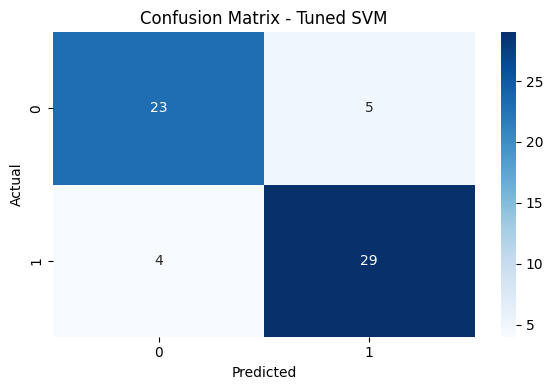

In [15]:
# Confusion matrix graph
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Tuned SVM")
plt.tight_layout()
plt.show()


In [16]:
# Save the trained SVM model and the fitted scaler using pickle.
os.makedirs("model", exist_ok=True)

model_path = os.path.join("model", "heart_disease_svm.pkl")
scaler_path = os.path.join("model", "scaler.pkl")

with open(model_path, "wb") as f:
    pickle.dump(best_model, f)

with open(scaler_path, "wb") as f:
    pickle.dump(scaler, f)

print("\nModel saved to:", model_path)
print("Scaler saved to:", scaler_path)



Model saved to: model\heart_disease_svm.pkl
Scaler saved to: model\scaler.pkl


In [17]:
# Load the saved model and scaler back from pickle.
with open(model_path, "rb") as f:
    loaded_model = pickle.load(f)

with open(scaler_path, "rb") as f:
    loaded_scaler = pickle.load(f)

loaded_pred = loaded_model.predict(X_test_scaled)
loaded_accuracy = accuracy_score(y_test, loaded_pred)

print("\nSaved model loaded successfully.")
print("Loaded model test accuracy: {:.2f}%".format(loaded_accuracy * 100))



Saved model loaded successfully.
Loaded model test accuracy: 85.25%


In [18]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in current folder:")
for file in os.listdir():
    print(file)

Current working directory:
c:\Users\kotha\Downloads\Heart_disease_svm

Files in current folder:
heart_disease_data.csv
model
scaler.pkl
svm_model.pkl
train_model_modified.ipynb


In [19]:
# ============================================================
# SAVE TRAINED SVM MODEL AND SCALER
# ============================================================

import pickle
import os

# Save the trained model
with open("svm_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

# Save the fitted scaler
with open("scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

print("Model and scaler saved successfully!")

print("\nModel file:")
print(os.path.abspath("svm_model.pkl"))

print("\nScaler file:")
print(os.path.abspath("scaler.pkl"))

Model and scaler saved successfully!

Model file:
c:\Users\kotha\Downloads\Heart_disease_svm\svm_model.pkl

Scaler file:
c:\Users\kotha\Downloads\Heart_disease_svm\scaler.pkl


## Terminal-style patient prediction

Run the next cell in VS Code/Jupyter. It asks for the 13 values used by this dataset and predicts using the saved SVM model. The input order is exactly the dataset feature order shown below.

**This is an educational model output, not a medical diagnosis.**

In [22]:
# ============================================================
# PART 4: NEW PATIENT INPUT AND PREDICTION
# ============================================================

import pandas as pd
import pickle
import os


# ------------------------------------------------------------
# 1. Define Feature Order
# ------------------------------------------------------------

feature_columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal"
]

print("\n" + "=" * 60)
print("FEATURE ORDER")
print("=" * 60)

print(feature_columns)


# ------------------------------------------------------------
# 2. Check Saved Model and Scaler
# ------------------------------------------------------------

model_path = "model/heart_disease_svm.pkl"
scaler_path = "model/scaler.pkl"

if not os.path.exists(model_path):
    raise FileNotFoundError(
        "heart_disease_svm.pkl not found. "
        "Please run PART 3 first."
    )

if not os.path.exists(scaler_path):
    raise FileNotFoundError(
        "scaler.pkl not found. "
        "Please run PART 3 first."
    )


# ------------------------------------------------------------
# 3. Load Saved Model
# ------------------------------------------------------------

with open(
    model_path,
    "rb"
) as file:

    loaded_model = pickle.load(file)


# ------------------------------------------------------------
# 4. Load Saved Scaler
# ------------------------------------------------------------

with open(
    scaler_path,
    "rb"
) as file:

    loaded_scaler = pickle.load(file)


print("\nModel and scaler loaded successfully!")


# ------------------------------------------------------------
# 5. Integer Input Function
# ------------------------------------------------------------

def get_int(
    prompt,
    min_value=None,
    max_value=None
):

    while True:

        try:

            value = int(
                input(prompt)
            )

            if (
                min_value is not None
                and value < min_value
            ):

                print(
                    f"Please enter a value >= "
                    f"{min_value}."
                )

                continue

            if (
                max_value is not None
                and value > max_value
            ):

                print(
                    f"Please enter a value <= "
                    f"{max_value}."
                )

                continue

            return value

        except ValueError:

            print(
                "Please enter a whole number."
            )


# ------------------------------------------------------------
# 6. Float Input Function
# ------------------------------------------------------------

def get_float(
    prompt,
    min_value=None,
    max_value=None
):

    while True:

        try:

            value = float(
                input(prompt)
            )

            if (
                min_value is not None
                and value < min_value
            ):

                print(
                    f"Please enter a value >= "
                    f"{min_value}."
                )

                continue

            if (
                max_value is not None
                and value > max_value
            ):

                print(
                    f"Please enter a value <= "
                    f"{max_value}."
                )

                continue

            return value

        except ValueError:

            print(
                "Please enter a number."
            )


# ------------------------------------------------------------
# 7. Enter Patient Details
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ENTER PATIENT DETAILS")
print("=" * 60)

print("\nPlease enter the patient's information.\n")


patient = {

    "age": get_int(
        "Age: ",
        1,
        120
    ),

    "sex": get_int(
        "Sex (0 or 1): ",
        0,
        1
    ),

    "cp": get_int(
        "Chest pain type (cp, 0-3): ",
        0,
        3
    ),

    "trestbps": get_int(
        "Resting blood pressure (trestbps): ",
        1
    ),

    "chol": get_int(
        "Cholesterol (chol): ",
        1
    ),

    "fbs": get_int(
        "Fasting blood sugar (fbs, 0 or 1): ",
        0,
        1
    ),

    "restecg": get_int(
        "Resting ECG (restecg, 0-2): ",
        0,
        2
    ),

    "thalach": get_int(
        "Maximum heart rate (thalach): ",
        1
    ),

    "exang": get_int(
        "Exercise-induced angina (exang, 0 or 1): ",
        0,
        1
    ),

    "oldpeak": get_float(
        "ST depression (oldpeak): ",
        0
    ),

    "slope": get_int(
        "Slope (slope, 0-2): ",
        0,
        2
    ),

    "ca": get_int(
        "Number of major vessels (ca, 0-4): ",
        0,
        4
    ),

    "thal": get_int(
        "Thalassemia (thal, 0-3): ",
        0,
        3
    )
}


# ------------------------------------------------------------
# 8. Convert Patient Data to DataFrame
# ------------------------------------------------------------

new_patient = pd.DataFrame(
    [patient],
    columns=feature_columns
)


print("\n" + "=" * 60)
print("PATIENT DETAILS")
print("=" * 60)

print(
    new_patient.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 9. Scale New Patient Data
# ------------------------------------------------------------

# IMPORTANT:
# Do NOT use fit_transform() here.
# The scaler was already fitted during PART 1.
# Only transform() is used for new patient data.

new_patient_scaled = loaded_scaler.transform(
    new_patient
)


# ------------------------------------------------------------
# 10. Make Prediction
# ------------------------------------------------------------

prediction = loaded_model.predict(new_patient_scaled)[0]

print("\n" + "=" * 60)
print("PREDICTION RESULT")
print("=" * 60)

prediction = int(prediction)

print("Prediction value:", prediction)

if prediction == 1:
    result = "Heart disease predicted by the model."
else:
    result = "No heart disease predicted by the model."

print("\nRESULT:", result)

print("\n" + "=" * 60)
print("PREDICTION COMPLETED")
print("=" * 60)

print("\nFINAL RESULT:", result)

print(
    "\nNote: This prediction is for educational/model-testing "
    "purposes and is not a medical diagnosis."
)


FEATURE ORDER
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Model and scaler loaded successfully!

ENTER PATIENT DETAILS

Please enter the patient's information.


PATIENT DETAILS
 age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  ca  thal
  48    1   0       130   256    1        0      150      1      0.0      2   2     3

PREDICTION RESULT
Prediction value: 0

RESULT: No heart disease predicted by the model.

PREDICTION COMPLETED

FINAL RESULT: No heart disease predicted by the model.

Note: This prediction is for educational/model-testing purposes and is not a medical diagnosis.
